In [ ]:
"""
Regrid land-sea mask and elevation data onto the native UK radar grid.

Set lsm_path and elev_path below.

Output files have dimensions (y, x) matching the raw radar resolution.
"""

import os
import numpy as np
import xarray as xr

from pyproj import CRS, Transformer

from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator
from scipy.spatial import Delaunay


# ============================================================
# PATHS
# ============================================================

lsm_path = "/network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/constants/lsm_30arcsec.nc"
elev_path = "/network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/constants/elevation_7.5arcsec.nc"

radar_path = (
    "/network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/example_grids/2026_radar_sample_grid_cropped_to_old_extent.nc"
)

output_dir = "/network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/new_radar_sample/constants"
os.makedirs(output_dir, exist_ok=True)


# ============================================================
# SETTINGS
# ============================================================

# Change these if the variables have different names in the files.
lsm_input_var = "lsm"
lsm_output_var = "lsm"

elev_input_var = "elevation"
elev_output_var = "elevation"

# Nearest-neighbour is preferable for a categorical/binary land-sea mask.
# Linear interpolation is appropriate for continuous elevation.
lsm_method = "conservative"
elev_method = "linear"

/home/m/matthewwright/nobackups/anaconda3/envs/initial-analysis/lib/python3.10/site-packages/xarray/backends/cfgrib_.py:29: UserWarning: Failed to load cfgrib - most likely there is a problem accessing the ecCodes library. Try `import cfgrib` to get the full error message
  warnings.warn(


In [4]:

# ============================================================
# LOAD NATIVE RADAR GRID
# ============================================================

print(f"Loading radar grid from:\n  {radar_path}")

with xr.open_dataset(radar_path) as radar:
    display(radar)
    radar_x = radar["x"].values
    radar_y = radar["y"].values
    radar_centre_lat = radar["central_lat"].values
    radar_centre_lon = radar["central_lon"].values
    radar_xr = radar.qpe

# Local azimuthal equidistant projection centred on radar
radar_crs = CRS.from_proj4(
    f"+proj=aeqd "
    f"+lat_0={radar_centre_lat} "
    f"+lon_0={radar_centre_lon} "
    f"+datum=WGS84 +units=m"
)

to_lonlat = Transformer.from_crs(
    radar_crs,
    "EPSG:4326",
    always_xy=True
)

# x and y are 1-D arrays in metres
radar_xx, radar_yy = np.meshgrid(radar_x, radar_y)

radar_lon, radar_lat = to_lonlat.transform(
    radar_xx,
    radar_yy
)


# NO COARSENING.
# radar_x/radar_y remain at the raw ~1 km radar resolution.

assert radar_lon.shape == radar_lat.shape
assert radar_lon.shape == (len(radar_y), len(radar_x))

print(f"Native radar grid: {len(radar_y)} x {len(radar_x)}")
print(f"Target shape: {radar_lon.shape}")

Loading radar grid from:
  /network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/example_grids/2026_radar_sample_grid_cropped_to_old_extent.nc


<xarray.Dataset>
Dimensions:      (y: 396, x: 396)
Coordinates:
    central_lon  float64 ...
    central_lat  float64 ...
  * y            (y) float64 -1.98e+05 -1.97e+05 -1.96e+05 ... 1.96e+05 1.97e+05
  * x            (x) float64 -1.98e+05 -1.97e+05 -1.96e+05 ... 1.96e+05 1.97e+05
    time         datetime64[ns] ...
    lon          (y, x) float64 ...
    lat          (y, x) float64 ...
Data variables:
    qpe          (y, x) float64 ...

Native radar grid: 396 x 396
Target shape: (396, 396)


In [5]:
radar_x

array([-198000., -197000., -196000., -195000., -194000., -193000.,
       -192000., -191000., -190000., -189000., -188000., -187000.,
       -186000., -185000., -184000., -183000., -182000., -181000.,
       -180000., -179000., -178000., -177000., -176000., -175000.,
       -174000., -173000., -172000., -171000., -170000., -169000.,
       -168000., -167000., -166000., -165000., -164000., -163000.,
       -162000., -161000., -160000., -159000., -158000., -157000.,
       -156000., -155000., -154000., -153000., -152000., -151000.,
       -150000., -149000., -148000., -147000., -146000., -145000.,
       -144000., -143000., -142000., -141000., -140000., -139000.,
       -138000., -137000., -136000., -135000., -134000., -133000.,
       -132000., -131000., -130000., -129000., -128000., -127000.,
       -126000., -125000., -124000., -123000., -122000., -121000.,
       -120000., -119000., -118000., -117000., -116000., -115000.,
       -114000., -113000., -112000., -111000., -110000., -1090

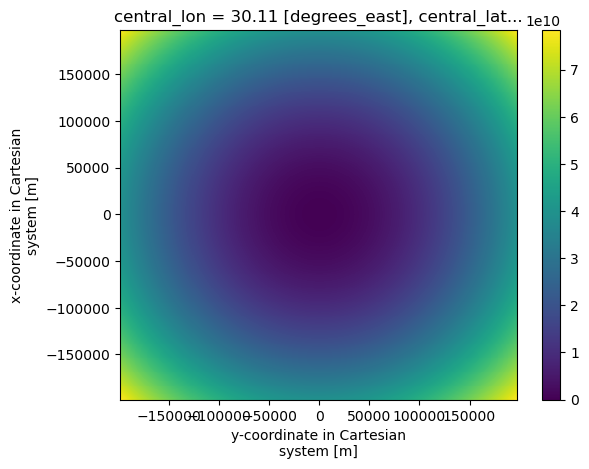

In [6]:
(np.abs((radar.x - radar.isel(x=len(radar.x)//2).x)**2 + (radar.y - radar.isel(y=len(radar.y)//2).y)**2)).plot()

In [7]:
# ============================================================
# HELPERS
# ============================================================

def find_coord(ds, candidates):
    """Return first matching coordinate or variable name."""
    for name in candidates:
        if name in ds.coords or name in ds.variables:
            return name

    raise KeyError(
        f"Could not find any of {candidates}.\n"
        f"Available variables: {list(ds.variables)}"
    )


def coord_bounds(coord):
    """
    Construct cell edges from 1D cell centres.

    Assumes a monotonic, approximately regular coordinate axis.
    """
    coord = np.asarray(coord, dtype=np.float64)

    if coord.ndim != 1 or coord.size < 2:
        raise ValueError("Expected a 1D coordinate with at least 2 values.")

    if not (
        np.all(np.diff(coord) > 0)
        or np.all(np.diff(coord) < 0)
    ):
        raise ValueError("Coordinates must be strictly monotonic.")

    edges = np.empty(coord.size + 1, dtype=np.float64)

    edges[1:-1] = 0.5 * (coord[:-1] + coord[1:])
    edges[0] = coord[0] - 0.5 * (coord[1] - coord[0])
    edges[-1] = coord[-1] + 0.5 * (coord[-1] - coord[-2])

    return edges


def prepare_source_grid(ds, var_name):
    """
    Prepare flattened source coordinates for SciPy interpolation.
    Supports 1D and 2D geographic coordinates.
    """
    lon_name = find_coord(ds, ["lon", "longitude"])
    lat_name = find_coord(ds, ["lat", "latitude"])

    lon = np.asarray(ds[lon_name].values)
    lat = np.asarray(ds[lat_name].values)

    da = ds[var_name].squeeze(drop=True)

    if lon.ndim == 1 and lat.ndim == 1:
        da = da.transpose(lat_name, lon_name)
        source_lon, source_lat = np.meshgrid(lon, lat)

    elif lon.ndim == 2 and lat.ndim == 2:
        if ds[lon_name].dims != ds[lat_name].dims:
            raise ValueError("Longitude/latitude dimensions differ.")

        da = da.transpose(*ds[lon_name].dims)
        source_lon = lon
        source_lat = lat

    else:
        raise ValueError("Unsupported source coordinate dimensions.")

    data = np.asarray(da.values)

    if np.nanmax(source_lon) > 180:
        source_lon = ((source_lon + 180) % 360) - 180

    valid = (
        np.isfinite(source_lon)
        & np.isfinite(source_lat)
        & np.isfinite(data)
    )

    return (
        source_lon[valid],
        source_lat[valid],
        data[valid],
        ds[var_name].attrs.copy(),
    )


def prepare_conservative_source(ds, var_name):
    """
    Prepare a rectilinear geographic source grid for xESMF.

    Source coordinates must be 1D longitude and latitude.
    """
    lon_name = find_coord(ds, ["lon", "longitude"])
    lat_name = find_coord(ds, ["lat", "latitude"])

    lon = np.asarray(ds[lon_name].values, dtype=np.float64)
    lat = np.asarray(ds[lat_name].values, dtype=np.float64)

    if lon.ndim != 1 or lat.ndim != 1:
        raise ValueError(
            "Conservative regridding currently requires "
            "1D source longitude and latitude."
        )

    da = ds[var_name].squeeze(drop=True).transpose(
        lat_name, lon_name
    )

    # Ensure increasing longitude
    if lon[0] > lon[-1]:
        lon = lon[::-1]
        da = da.isel({lon_name: slice(None, None, -1)})

    # Ensure increasing latitude
    if lat[0] > lat[-1]:
        lat = lat[::-1]
        da = da.isel({lat_name: slice(None, None, -1)})

    if np.nanmax(lon) > 180:
        lon = ((lon + 180) % 360) - 180

        # Ensure ordering remains increasing after conversion
        order = np.argsort(lon)
        lon = lon[order]
        da = da.isel({lon_name: order})

    lon_b = coord_bounds(lon)
    lat_b = coord_bounds(lat)

    grid = xr.Dataset(
        coords={
            "lon": ("x", lon),
            "lat": ("y", lat),
            "lon_b": ("x_b", lon_b),
            "lat_b": ("y_b", lat_b),
        }
    )

    field = xr.DataArray(
        da.values.astype(np.float64),
        dims=("y", "x"),
        name=var_name,
    )

    # Explicitly attach geographic centre coordinates
    field = field.assign_coords(
        lon=("x", lon),
        lat=("y", lat),
    )

    return grid, field


def prepare_conservative_target(
    radar_x,
    radar_y,
    radar_crs,
):
    """
    Construct geographic centre and corner coordinates
    from a regular projected radar grid.
    """
    x = np.asarray(radar_x, dtype=np.float64)
    y = np.asarray(radar_y, dtype=np.float64)

    if x.ndim != 1 or y.ndim != 1:
        raise ValueError("radar_x and radar_y must be 1D.")

    x_b = coord_bounds(x)
    y_b = coord_bounds(y)

    transformer = Transformer.from_crs(
        radar_crs,
        "EPSG:4326",
        always_xy=True,
    )

    xc, yc = np.meshgrid(x, y)
    lon, lat = transformer.transform(xc, yc)

    xb, yb = np.meshgrid(x_b, y_b)
    lon_b, lat_b = transformer.transform(xb, yb)

    return xr.Dataset(
        coords={
            "lon": (("y", "x"), lon),
            "lat": (("y", "x"), lat),
            "lon_b": (("y_b", "x_b"), lon_b),
            "lat_b": (("y_b", "x_b"), lat_b),
        }
    )


# ============================================================
# REGRIDDING
# ============================================================

def regrid_file(input_path, var_name, method):
    """Regrid one field to the native radar grid."""

    print()
    print("=" * 60)
    print(f"Loading: {input_path}")
    print(f"Variable: {var_name}")
    print(f"Method: {method}")

    with xr.open_dataset(input_path) as ds:
        # Crop to radar domain with 0.1 degree buffer
        buffer = 0.1

        lon_min = np.nanmin(radar_lon) - buffer
        lon_max = np.nanmax(radar_lon) + buffer
        lat_min = np.nanmin(radar_lat) - buffer
        lat_max = np.nanmax(radar_lat) + buffer

        lon_name = find_coord(ds, ["lon", "longitude"])
        lat_name = find_coord(ds, ["lat", "latitude"])

        # Handle ascending or descending coordinates
        lon_slice = (
            slice(lon_min, lon_max)
            if ds[lon_name][0] < ds[lon_name][-1]
            else slice(lon_max, lon_min)
        )

        lat_slice = (
            slice(lat_min, lat_max)
            if ds[lat_name][0] < ds[lat_name][-1]
            else slice(lat_max, lat_min)
        )

        ds = ds.sel({
            lon_name: lon_slice,
            lat_name: lat_slice,
        })

        print(f"Cropped source shape: {ds[var_name].shape}")


        attrs = ds[var_name].attrs.copy()

        if method == "conservative":
            import xesmf as xe

            source_grid, source_field = (
                prepare_conservative_source(ds, var_name)
            )

            target_grid = prepare_conservative_target(
                radar_x,
                radar_y,
                radar_crs,
            )

            print("Constructing conservative weights...")

            regridder = xe.Regridder(
                source_grid,
                target_grid,
                method="conservative",
                periodic=False,
                unmapped_to_nan=True,
            )

            print("Regridding...")
            output = regridder(source_field).values

        elif method in ("linear", "nearest"):

            source_lon, source_lat, source_data, attrs = (
                prepare_source_grid(ds, var_name)
            )

            print(f"Valid source points: {len(source_data):,}")

            points = np.column_stack(
                (source_lon, source_lat)
            )

            if method == "linear":
                print("Constructing Delaunay triangulation...")
                tri = Delaunay(points)

                interp = LinearNDInterpolator(
                    tri,
                    source_data,
                    fill_value=np.nan,
                )

            else:
                print("Constructing nearest-neighbour interpolator...")
                interp = NearestNDInterpolator(
                    points,
                    source_data,
                )

            print("Interpolating...")
            output = interp(radar_lon, radar_lat)

        else:
            raise ValueError(
                f"Unknown interpolation method: {method}"
            )

    if output.shape != radar_lon.shape:
        raise ValueError(
            f"Output shape {output.shape} does not match "
            f"radar grid {radar_lon.shape}"
        )

    output = np.asarray(output, dtype=np.float32)

    print(f"Output shape: {output.shape}")
    print(f"Valid output cells: {np.isfinite(output).sum():,}")

    return output, attrs


# ============================================================
# SAVE OUTPUT
# ============================================================

def save_output(output_path, var_name, data, attrs, method):
    """Save regridded field with native radar coordinates."""

    ds_out = xr.Dataset(
        data_vars={
            var_name: (
                ("y", "x"),
                data,
                attrs,
            ),
        },
        coords={
            "x": (
                "x",
                np.asarray(radar_x, dtype=np.float32),
                {"units": "m"},
            ),
            "y": (
                "y",
                np.asarray(radar_y, dtype=np.float32),
                {"units": "m"},
            ),
            "lon": (
                ("y", "x"),
                np.asarray(radar_lon, dtype=np.float32),
                {"units": "degrees_east"},
            ),
            "lat": (
                ("y", "x"),
                np.asarray(radar_lat, dtype=np.float32),
                {"units": "degrees_north"},
            ),
        },
    )

    ds_out.attrs.update({
        "description": (
            f"{var_name} regridded to native radar resolution"
        ),
        "radar_grid_source": str(radar_path),
        "regridding_method": method,
    })

    encoding = {
        var_name: {
            "zlib": True,
            "complevel": 4,
            "dtype": "float32",
        }
    }

    ds_out.to_netcdf(
        output_path,
        encoding=encoding,
    )

    print(f"Saved: {output_path}")


# ============================================================
# LAND-SEA MASK
# ============================================================

lsm, lsm_attrs = regrid_file(
    lsm_path,
    lsm_input_var,
    method=lsm_method,
)

lsm_attrs["long_name"] = "Land fraction"
lsm_attrs["units"] = "1"
lsm_attrs["regridding_method"] = lsm_method

# IMPORTANT:
# This assumes input = 1 for land and 0 for water.
# If your ESA variable instead marks permanent water as 1,
# this is water fraction, not land fraction.
# In that case, use lsm = 1.0 - lsm only if you want land fraction.

save_output(
    os.path.join(output_dir, "lsm.nc"),
    lsm_output_var,
    lsm,
    lsm_attrs,
    lsm_method,
)


# ============================================================
# ELEVATION
# ============================================================

elev, elev_attrs = regrid_file(
    elev_path,
    elev_input_var,
    method=elev_method,
)

# GMTED2010 elevation is already in metres.
# Do NOT divide by 9.81.

elev_attrs.update({
    "long_name": "Elevation",
    "standard_name": "surface_altitude",
    "units": "m",
    "source": "USGS GMTED2010",
    "regridding_method": elev_method,
})

save_output(
    os.path.join(output_dir, "elev.nc"),
    elev_output_var,
    elev,
    elev_attrs,
    elev_method,
)

print()
print("Done.")


Loading: /network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/constants/lsm_30arcsec.nc
Variable: lsm
Method: conservative
Cropped source shape: (453, 450)
Constructing conservative weights...
Regridding...
Output shape: (396, 396)
Valid output cells: 156,816
Saved: /network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/new_radar_sample/lsm.nc

Loading: /network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/constants/elevation_7.5arcsec.nc
Variable: elevation
Method: linear
Cropped source shape: (1811, 1803)
Valid source points: 3,265,233
Constructing Delaunay triangulation...
Interpolating...
Output shape: (396, 396)
Valid output cells: 156,816
Saved: /network/group/aopp/predict/AWH029_WRIGHT_S2SPREC/rwanda_radar_data/new_radar_sample/elev.nc

Done.


/tmp/user/26999/ipykernel_1688827/1031761476.py:40: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  mesh = ax.pcolormesh(


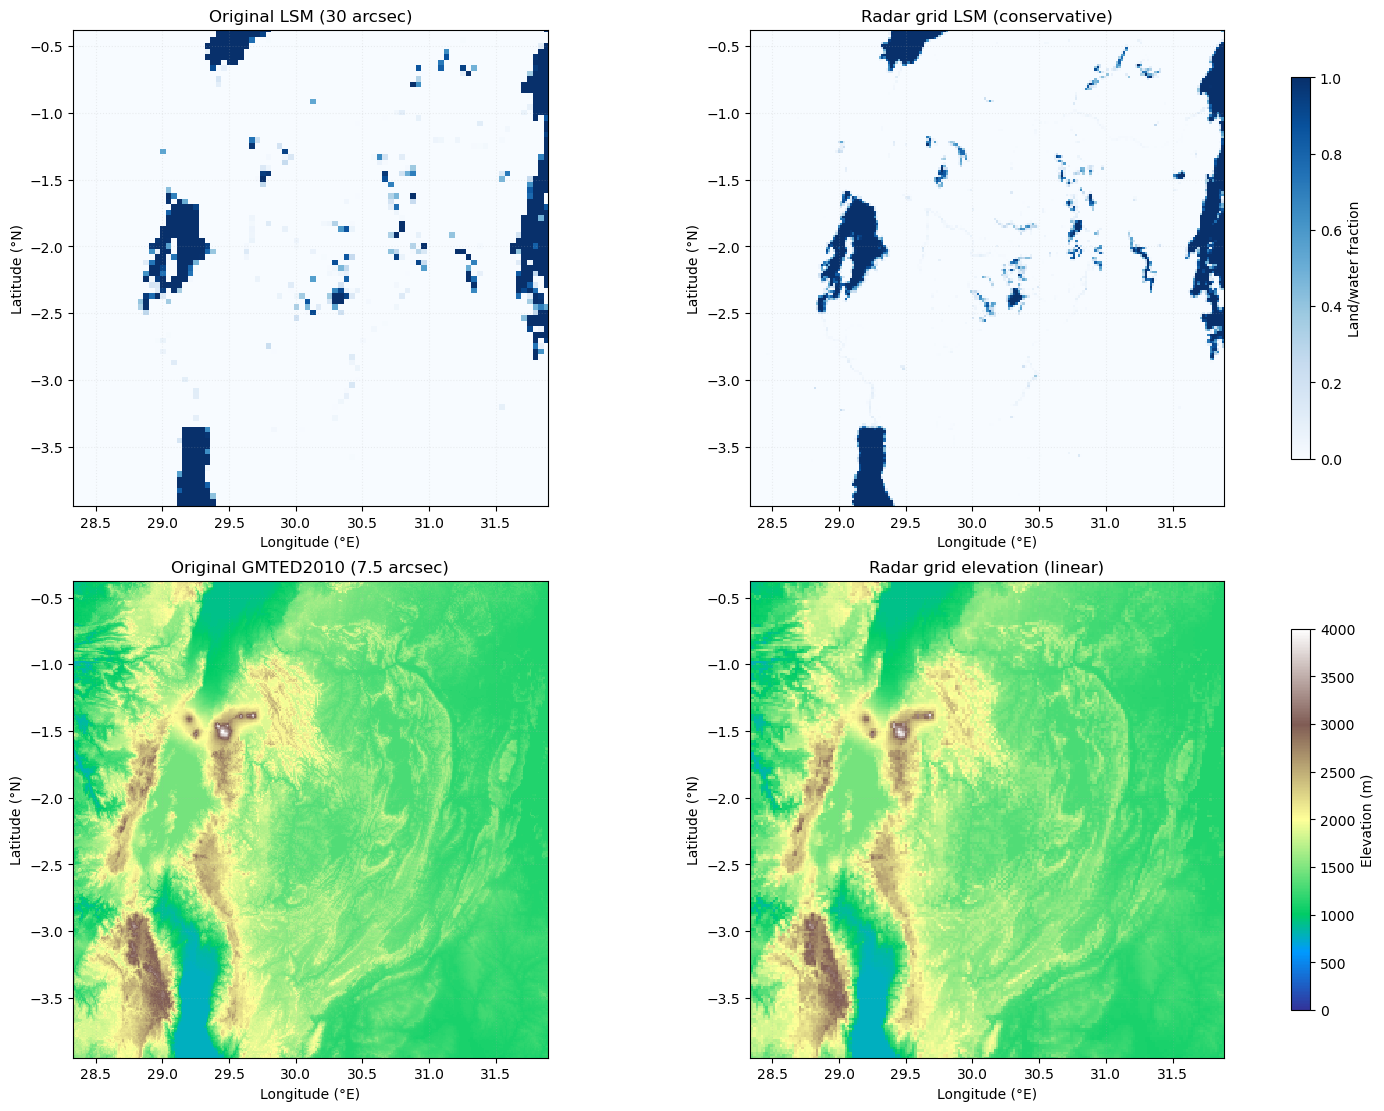

In [8]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# ============================================================
# SETTINGS
# ============================================================

# Downsampling for display only
source_step = 5
radar_step = 2

# Geographic extent of radar grid
extent = [
    np.nanmin(radar_lon),
    np.nanmax(radar_lon),
    np.nanmin(radar_lat),
    np.nanmax(radar_lat),
]

# ============================================================
# HELPER: PLOT SOURCE OR REGRIDDED FIELD
# ============================================================

def plot_field(ax, lon, lat, data, title, cmap, vmin, vmax,
               step=1):

    lon = np.asarray(lon)
    lat = np.asarray(lat)
    data = np.asarray(data)

    # Handle 1D source coordinates
    if lon.ndim == 1 and lat.ndim == 1:
        lon, lat = np.meshgrid(lon[::step], lat[::step])
        data = data[::step, ::step]
    else:
        lon = lon[::step, ::step]
        lat = lat[::step, ::step]
        data = data[::step, ::step]

    mesh = ax.pcolormesh(
        lon,
        lat,
        data,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        shading="auto",
        rasterized=True,
    )

    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")

    ax.set_title(title)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    ax.grid(alpha=0.2, linestyle=":")

    return mesh


# ============================================================
# LOAD ORIGINAL DATA
# ============================================================

with xr.open_dataset(lsm_path) as ds_lsm:
    lsm_source = ds_lsm[lsm_input_var].squeeze().load()
    lsm_source_lon = ds_lsm[
        find_coord(ds_lsm, ["lon", "longitude"])
    ].values
    lsm_source_lat = ds_lsm[
        find_coord(ds_lsm, ["lat", "latitude"])
    ].values

with xr.open_dataset(elev_path) as ds_elev:
    elev_source = ds_elev[elev_input_var].squeeze().load()
    elev_source_lon = ds_elev[
        find_coord(ds_elev, ["lon", "longitude"])
    ].values
    elev_source_lat = ds_elev[
        find_coord(ds_elev, ["lat", "latitude"])
    ].values


# ============================================================
# PLOT COMPARISON
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 11),
    constrained_layout=True
)

# Land/water mask
m1 = plot_field(
    axes[0, 0],
    lsm_source_lon,
    lsm_source_lat,
    lsm_source.values,
    "Original LSM (30 arcsec)",
    cmap="Blues",
    vmin=0,
    vmax=1,
    step=source_step,
)

m2 = plot_field(
    axes[0, 1],
    radar_lon,
    radar_lat,
    lsm,
    f"Radar grid LSM ({lsm_method})",
    cmap="Blues",
    vmin=0,
    vmax=1,
    step=radar_step,
)

# Elevation
m3 = plot_field(
    axes[1, 0],
    elev_source_lon,
    elev_source_lat,
    elev_source.values,
    "Original GMTED2010 (7.5 arcsec)",
    cmap="terrain",
    vmin=0,
    vmax=4000,
    step=source_step,
)

m4 = plot_field(
    axes[1, 1],
    radar_lon,
    radar_lat,
    elev,
    f"Radar grid elevation ({elev_method})",
    cmap="terrain",
    vmin=0,
    vmax=4000,
    step=radar_step,
)

fig.colorbar(
    m2,
    ax=axes[0, :],
    label="Land/water fraction",
    shrink=0.8,
)

fig.colorbar(
    m4,
    ax=axes[1, :],
    label="Elevation (m)",
    shrink=0.8,
)

plt.show()

In [9]:
lsm_source

<xarray.DataArray 'lsm' (latitude: 840, longitude: 840)>
array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)
Coordinates:
  * longitude  (longitude) float32 26.0 26.01 26.02 26.03 ... 32.98 32.99 33.0
  * latitude   (latitude) float32 -5.996 -5.988 -5.979 ... 0.979 0.9874 0.9957
Attributes:
    description:       Proportion of the grid cell with permanent water bodies.
    long_description:  This class includes any geographic area covered for mo...